# ДЗ №2. Как объединить оценки асессоров

Задача — восстановить итоговую метку комментария к футбольному матчу по ответам нескольких асессоров. Классов три: негативный, нейтральный и позитивный. Сравниваю **Majority Vote**, **Weighted Majority Vote** и **Dawid–Skene**.

Данные синтетические: у каждого задания есть скрытая эталонная метка, поэтому качество методов можно измерить честно. Генератор воспроизводит свойства реальной краудразметки: разный опыт и загрузку асессоров, разную сложность заданий, систематические ошибки и калибровочные (gold) задания.

Ноутбук запускается сверху вниз. Нужны NumPy, pandas, Matplotlib, scikit-learn, Jinja2 и Jupyter.

## 1. Как устроена симуляция

- **2 000 заданий и 40 асессоров.** 400 заданий (20%) — калибровочные: их эталонные метки доступны для оценки качества асессоров. Остальные 1 600 — тестовые: их метки открываются только при подсчёте метрик.
- На задание назначаются **3, 4, 5 или 7 асессоров**; среднее перекрытие около 4.
- Опыт асессоров неоднороден: 10 сильных (0.85–0.96), 21 средний (0.68–0.83) и 9 слабых (0.47–0.65). Загрузка распределена логнормально: есть «тяжёлые» исполнители, которые берут больше заданий.
- Сложность задания снижает вероятность правильного ответа; нейтральный класс дополнительно чуть сложнее.
- При ошибке асессор чаще путает соседние по тональности классы (негатив↔нейтраль, позитив↔нейтраль), а также имеет личную склонность к одному из ответов.
- Методы видят только оценки. Эталонные метки тестовых заданий используются только для оценки качества. Weighted Majority Vote использует gold калибровки, Dawid–Skene — нет.

В таблицах код 0 означает негативный класс, 1 — нейтральный, 2 — позитивный.

In [1]:
from __future__ import annotations

from collections.abc import Iterable, Sequence
from dataclasses import dataclass
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    recall_score,
)

### Настройки

In [2]:
SEED = 42
N_BOOTSTRAP = 3_000
BOOTSTRAP_SEED = SEED + 1
ROBUSTNESS_SEEDS = (42, 43, 44, 45, 46)
EXPORT_CSV = False
OUT_DIR = Path("assessor_data")

CLASS_NAMES = ["Негативный", "Нейтральный", "Позитивный"]
LEVELS = ["Лёгкие", "Средние", "Сложные"]
CLASS_IDS = np.arange(len(CLASS_NAMES))
METHODS = ("Majority Vote", "Weighted Majority Vote", "Dawid–Skene")
METHOD_COLORS = {
    "Majority Vote": "#315f93",
    "Weighted Majority Vote": "#258278",
    "Dawid–Skene": "#c57640",
}
BLUE, TEAL, ORANGE = METHOD_COLORS.values()

plt.rcParams.update(
    {
        "figure.dpi": 105,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#314155",
        "text.color": "#24364b",
    }
)

### Параметры генератора и агрегации

Все параметры собраны в типизированные конфигурации. Гиперпараметры агрегации фиксированы заранее и не подбираются по тесту.

In [3]:
ERROR_PATTERN = np.array(
    [
        [0.00, 0.83, 0.17],
        [0.55, 0.00, 0.45],
        [0.17, 0.83, 0.00],
    ]
)


@dataclass(frozen=True)
class SimulationConfig:
    n_tasks: int = 2_000
    n_workers: int = 40
    n_calibration: int = 400
    class_probs: tuple[float, float, float] = (0.28, 0.42, 0.30)
    difficulty_probs: tuple[float, float, float] = (0.43, 0.39, 0.18)
    difficulty_penalty: tuple[float, float, float] = (0.00, 0.12, 0.29)
    neutral_penalty: float = 0.05
    n_votes_values: tuple[int, ...] = (3, 4, 5, 7)
    n_votes_probs: tuple[float, ...] = (0.37, 0.30, 0.24, 0.09)
    skill_ranges: tuple[tuple[float, float], ...] = (
        (0.85, 0.96),
        (0.68, 0.83),
        (0.47, 0.65),
    )
    skill_counts: tuple[int, ...] = (10, 21, 9)
    activity_sigma: float = 0.5
    preferred_alpha: tuple[float, float, float] = (2.0, 4.0, 2.0)
    error_mix: float = 0.6
    min_accuracy: float = 0.23
    max_accuracy: float = 0.97


@dataclass(frozen=True)
class AggregationConfig:
    prior_strength: float = 10.0
    ds_smoothing: float = 0.5
    ds_max_iter: int = 200
    ds_tol: float = 1e-6


SIM_CONFIG = SimulationConfig()
AGG_CONFIG = AggregationConfig()

### Типы данных

In [4]:
@dataclass(frozen=True)
class WorkerParams:
    skill: np.ndarray
    activity: np.ndarray
    preferred: np.ndarray


@dataclass(frozen=True)
class SimulationData:
    tasks: pd.DataFrame
    annotations: pd.DataFrame


@dataclass(frozen=True)
class VoteTable:
    scores: np.ndarray
    item_rows: np.ndarray
    worker_ids: np.ndarray
    labels: np.ndarray

    @property
    def popularity(self) -> np.ndarray:
        return self.scores.sum(axis=0)


@dataclass(frozen=True)
class DawidSkeneResult:
    posterior: np.ndarray
    confusion: np.ndarray
    objective: np.ndarray
    iterations: int
    converged: bool


@dataclass(frozen=True)
class PipelineResult:
    votes: VoteTable
    weights: np.ndarray
    predictions: dict[str, np.ndarray]
    ds: DawidSkeneResult

## 2. Генерация данных

In [5]:
def _sample_tasks(rng: np.random.Generator, config: SimulationConfig) -> pd.DataFrame:
    """Draw gold labels, difficulty levels and the calibration/test split."""
    gold = rng.choice(CLASS_IDS, size=config.n_tasks, p=config.class_probs)
    difficulty = rng.choice(len(LEVELS), size=config.n_tasks, p=config.difficulty_probs)
    calibration_ids = np.sort(
        rng.choice(config.n_tasks, config.n_calibration, replace=False)
    )
    split = np.full(config.n_tasks, "test", dtype=object)
    split[calibration_ids] = "calibration"
    return pd.DataFrame(
        {
            "task_id": np.arange(config.n_tasks),
            "split": split,
            "difficulty": np.asarray(LEVELS)[difficulty],
            "gold_label": gold,
        }
    )

In [6]:
def _sample_workers(rng: np.random.Generator, config: SimulationConfig) -> WorkerParams:
    """Draw per-worker skill, workload and answer preference."""
    assert sum(config.skill_counts) == config.n_workers
    skill = np.concatenate(
        [
            rng.uniform(low, high, count)
            for (low, high), count in zip(
                config.skill_ranges, config.skill_counts, strict=True
            )
        ]
    )
    rng.shuffle(skill)
    activity = rng.lognormal(0.0, config.activity_sigma, config.n_workers)
    activity /= activity.sum()
    preferred = rng.dirichlet(config.preferred_alpha, config.n_workers)
    return WorkerParams(skill=skill, activity=activity, preferred=preferred)

In [7]:
def _sample_annotations(
    rng: np.random.Generator,
    tasks: pd.DataFrame,
    workers: WorkerParams,
    config: SimulationConfig,
) -> pd.DataFrame:
    """Sample worker answers from the skill-and-difficulty model."""
    n_votes = rng.choice(
        config.n_votes_values, size=config.n_tasks, p=config.n_votes_probs
    )
    difficulty_index = np.array([LEVELS.index(level) for level in tasks["difficulty"]])
    gold = tasks["gold_label"].to_numpy()
    rows: list[tuple[int, int, int]] = []

    for task_id, truth in enumerate(gold):
        assigned = rng.choice(
            config.n_workers,
            n_votes[task_id],
            replace=False,
            p=workers.activity,
        )
        for worker in assigned:
            p_correct = np.clip(
                workers.skill[worker]
                - config.difficulty_penalty[difficulty_index[task_id]]
                - config.neutral_penalty * (truth == 1),
                config.min_accuracy,
                config.max_accuracy,
            )
            answer = truth
            if rng.random() >= p_correct:
                error_probs = (
                    config.error_mix * ERROR_PATTERN[truth]
                    + (1.0 - config.error_mix) * workers.preferred[worker]
                ).copy()
                error_probs[truth] = 0.0
                answer = rng.choice(CLASS_IDS, p=error_probs / error_probs.sum())
            rows.append((task_id, int(worker), int(answer)))

    return pd.DataFrame(rows, columns=["task_id", "worker_id", "label"])

In [8]:
def simulate_dataset(config: SimulationConfig, seed: int) -> SimulationData:
    """Generate a reproducible synthetic assessor dataset."""
    rng = np.random.default_rng(seed)
    tasks = _sample_tasks(rng, config)
    workers = _sample_workers(rng, config)
    annotations = _sample_annotations(rng, tasks, workers, config)

    assert annotations["task_id"].nunique() == config.n_tasks
    assert not annotations.duplicated(["task_id", "worker_id"]).any()
    sizes = annotations.groupby("task_id").size()
    assert sizes.between(min(config.n_votes_values), max(config.n_votes_values)).all()
    assert annotations["label"].isin(CLASS_IDS).all()
    assert (tasks["split"].eq("calibration").sum()) == config.n_calibration
    return SimulationData(tasks=tasks, annotations=annotations)

In [9]:
data = simulate_dataset(SIM_CONFIG, SEED)
tasks = data.tasks
annotations = data.annotations

if EXPORT_CSV:
    OUT_DIR.mkdir(exist_ok=True)
    tasks.to_csv(OUT_DIR / "tasks.csv", index=False)
    annotations.to_csv(OUT_DIR / "annotations.csv", index=False)

display(annotations.head(8))
print(f"Заданий: {len(tasks)} | оценок: {len(annotations)}")
print(
    f"Калибровка: {(tasks['split'].eq('calibration')).sum()} заданий | тест: {(tasks['split'].eq('test')).sum()}"
)

,task_id,worker_id,label
0,0,28,2
1,0,34,1
2,0,17,0
3,1,2,1
4,1,22,2
5,1,34,2
6,1,26,1
7,2,14,2


Заданий: 2000 | оценок: 8156
Калибровка: 400 заданий | тест: 1600


## 3. Статистики датасета

Смотрю на перекрытие разметки, нагрузку асессоров, согласие и распределение классов. Для каждого задания считаю долю совпавших пар асессоров, затем усредняю по заданиям. Дополнительно считаю **Krippendorff's alpha (nominal)** — коэффициент согласия, который корректно работает при разном числе оценок на задание.

Правильность ответов асессоров проверяю на 400 калибровочных заданиях. На остальных 1 600 заданиях эталонные метки использую только для итоговой оценки методов.

In [10]:
def pairwise_agreement(counts: np.ndarray) -> np.ndarray:
    """Share of matching rater pairs for every item."""
    sizes = counts.sum(axis=1)
    assert np.all(sizes >= 2)
    return (counts * (counts - 1.0)).sum(axis=1) / (sizes * (sizes - 1.0))


def krippendorff_alpha_nominal(units: Iterable[Sequence[int]], n_labels: int) -> float:
    """Compute nominal Krippendorff's alpha for units with >= 2 ratings.

    The coincidence matrix counts every ordered pair inside a unit and
    normalises by m - 1, so each unit contributes exactly m ratings.
    """
    coincidence = np.zeros((n_labels, n_labels), dtype=float)

    for ratings in units:
        values = np.asarray(ratings, dtype=int)
        size = values.size
        if size < 2:
            continue
        assert values.min() >= 0 and values.max() < n_labels
        counts = np.bincount(values, minlength=n_labels).astype(float)
        block = np.outer(counts, counts) / (size - 1)
        np.fill_diagonal(block, counts * (counts - 1) / (size - 1))
        coincidence += block

    total = coincidence.sum()
    if total <= 1:
        return float("nan")
    marginals = coincidence.sum(axis=1)
    observed = coincidence.sum() - np.trace(coincidence)
    expected = (marginals * (total - marginals)).sum() / (total - 1)
    if expected == 0:
        return float("nan")
    return float(1.0 - observed / expected)


def task_rating_units(annotations: pd.DataFrame) -> list[np.ndarray]:
    """Group annotations into per-task rating arrays."""
    return [
        group["label"].to_numpy()
        for _, group in annotations.groupby("task_id", sort=True)
    ]

In [11]:
# Known cases: perfect agreement => alpha = 1, one disagreement => alpha = 0.
assert np.isclose(krippendorff_alpha_nominal([[0, 0], [1, 1], [2, 2]], n_labels=3), 1.0)
assert np.isclose(krippendorff_alpha_nominal([[0, 0], [0, 1]], n_labels=2), 0.0)

In [12]:
def compute_worker_stats(
    tasks: pd.DataFrame,
    annotations: pd.DataFrame,
    n_workers: int,
) -> tuple[pd.DataFrame, float]:
    """Estimate worker accuracy on gold calibration tasks only."""
    calibration = tasks.loc[tasks["split"].eq("calibration"), ["task_id", "gold_label"]]
    calib = annotations.merge(calibration, on="task_id", validate="many_to_one")
    calib = calib.assign(correct=calib["label"].eq(calib["gold_label"]))
    stats = (
        calib.groupby("worker_id")["correct"]
        .agg(answers="size", correct="sum")
        .reindex(range(n_workers), fill_value=0)
    )
    stats["calib_accuracy"] = stats["correct"].div(stats["answers"].replace(0, np.nan))
    return stats, float(calib["correct"].mean())

### Сводные статистики

In [13]:
def build_vote_table(
    tasks: pd.DataFrame, annotations: pd.DataFrame, n_classes: int
) -> VoteTable:
    """Build per-task vote counts and annotation-to-task indices."""
    item_rows = pd.Index(tasks["task_id"]).get_indexer(annotations["task_id"])
    assert (item_rows >= 0).all()
    scores = np.zeros((len(tasks), n_classes), dtype=float)
    np.add.at(
        scores,
        (item_rows, annotations["label"].to_numpy()),
        1.0,
    )
    return VoteTable(
        scores=scores,
        item_rows=item_rows,
        worker_ids=annotations["worker_id"].to_numpy(),
        labels=annotations["label"].to_numpy(),
    )


votes = build_vote_table(tasks, annotations, len(CLASS_IDS))
counts = votes.scores
sizes = counts.sum(axis=1).astype(int)
pair_agreement = pairwise_agreement(counts)
unanimous = counts.max(axis=1) == sizes
tied = (counts == counts.max(axis=1, keepdims=True)).sum(axis=1) > 1

per_task = tasks.assign(
    ratings=sizes,
    agreement=pair_agreement,
    unanimous=unanimous,
    tied=tied,
)
workload = (
    annotations.groupby("worker_id")
    .size()
    .reindex(range(SIM_CONFIG.n_workers), fill_value=0)
)
worker_stats, calib_rate = compute_worker_stats(
    tasks, annotations, SIM_CONFIG.n_workers
)

alpha_all = krippendorff_alpha_nominal(task_rating_units(annotations), len(CLASS_IDS))
alpha_by_level = {}
for level in LEVELS:
    level_ids = set(tasks.loc[tasks["difficulty"].eq(level), "task_id"])
    units = [
        group["label"].to_numpy()
        for task_id, group in annotations.groupby("task_id")
        if task_id in level_ids
    ]
    alpha_by_level[level] = krippendorff_alpha_nominal(units, len(CLASS_IDS))

by_split = (
    per_task.groupby("split")
    .agg(Задания=("task_id", "size"), Оценки=("ratings", "sum"))
    .rename(index={"calibration": "Калибровка", "test": "Тест"})
)
by_level = (
    per_task.groupby("difficulty")
    .agg(
        Задания=("task_id", "size"),
        Согласие=("agreement", "mean"),
        Единогласие=("unanimous", "mean"),
        Ничьи=("tied", "mean"),
    )
    .reindex(LEVELS)
)
by_level["α"] = [alpha_by_level[level] for level in LEVELS]
by_level.loc["Все"] = [
    len(tasks),
    pair_agreement.mean(),
    unanimous.mean(),
    tied.mean(),
    alpha_all,
]

class_share = pd.DataFrame(
    {
        "Эталон": np.bincount(tasks["gold_label"], minlength=len(CLASS_IDS))
        / len(tasks),
        "Ответы асессоров": counts.sum(axis=0) / counts.sum(),
    },
    index=CLASS_NAMES,
)

print(
    f"Оценок на задание: {sizes.mean():.2f} в среднем, "
    f"{int(sizes.min())}–{int(sizes.max())}"
)
print(
    f"Оценок на асессора: {int(workload.min())}–{int(workload.max())}; "
    f"медиана {int(workload.median())}"
)
print(f"Точность одной оценки на калибровке: {calib_rate:.1%}")
print(f"Krippendorff's alpha: {alpha_all:.3f}")
display(by_split)
display(
    by_level.style.format(
        {
            "Задания": "{:.0f}",
            "Согласие": "{:.1%}",
            "Единогласие": "{:.1%}",
            "Ничьи": "{:.1%}",
            "α": "{:.3f}",
        }
    )
)
display(class_share.style.format("{:.1%}"))

Оценок на задание: 4.08 в среднем, 3–7
Оценок на асессора: 59–508; медиана 171
Точность одной оценки на калибровке: 61.4%
Krippendorff's alpha: 0.203


,Задания,Оценки
split,,
Калибровка,400,1646
Тест,1600,6510


,Задания,Согласие,Единогласие,Ничьи,α
difficulty,,,,,
Лёгкие,873,54.6%,26.0%,9.3%,0.310
Средние,780,44.7%,14.7%,15.5%,0.161
Сложные,347,36.3%,7.2%,18.4%,0.029
Все,2000,47.6%,18.4%,13.3%,0.203


,Эталон,Ответы асессоров
Негативный,28.1%,29.7%
Нейтральный,40.9%,40.3%
Позитивный,30.9%,30.0%


### Графики статистик

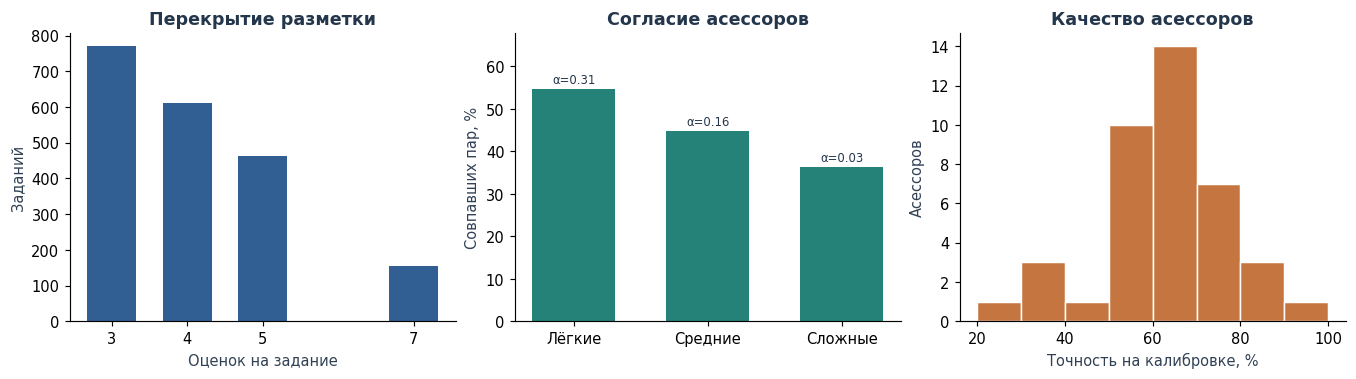

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.5), layout="constrained")

ratings_distribution = pd.Series(sizes).value_counts().sort_index()
axes[0].bar(
    ratings_distribution.index,
    ratings_distribution.to_numpy(),
    color=BLUE,
    width=0.65,
)
axes[0].set(
    title="Перекрытие разметки",
    xlabel="Оценок на задание",
    ylabel="Заданий",
    xticks=ratings_distribution.index,
)

agreement_by_level = 100 * by_level.loc[LEVELS, "Согласие"].to_numpy()
axes[1].bar(LEVELS, agreement_by_level, color=TEAL, width=0.62)
for position, level in enumerate(LEVELS):
    axes[1].text(
        position,
        agreement_by_level[position] + 1.5,
        f"α={alpha_by_level[level]:.2f}",
        ha="center",
        fontsize=8,
    )
axes[1].set(
    title="Согласие асессоров",
    ylabel="Совпавших пар, %",
    ylim=(0, 68),
)

axes[2].hist(
    100 * worker_stats["calib_accuracy"].dropna(),
    bins=np.arange(20, 101, 10),
    color=ORANGE,
    edgecolor="white",
)
axes[2].set(
    title="Качество асессоров",
    xlabel="Точность на калибровке, %",
    ylabel="Асессоров",
)
plt.show()

## 4. Агрегация

**Majority Vote.** Считаю голоса по каждому классу и выбираю класс с наибольшим числом голосов. При ничьей выбираю тот из равных классов, который чаще встречается среди всех наблюдаемых ответов (эталонные метки не нужны).

**Weighted Majority Vote.** Вес асессора — сглаженная точность на калибровке:

$$w_i = \frac{c_i + 10a}{n_i + 10},$$

где $c_i$ — правильные ответы, $n_i$ — число калибровочных ответов, $a$ — общая точность калибровочных ответов. Сглаживание уменьшает влияние пары случайных удач или ошибок. Затем складываю веса голосов по классам; правило ничьей то же.

**Dawid–Skene.** У каждого асессора своя матрица ошибок $3 \times 3$: в строке предполагаемый правильный класс, в столбце — поставленный асессором класс. EM-алгоритм поочерёдно оценивает матрицы ошибок и вероятности правильных меток. На M-шаге оцениваю частоты классов и матрицы ошибок; на E-шаге пересчитываю вероятности меток. Использую все 8 156 оценок, включая калибровочные, но **не использую gold**. Вычисления идут в логарифмах, небольшое сглаживание защищает от нулевых вероятностей.

In [15]:
def choose_vote(scores: np.ndarray, popularity: np.ndarray) -> np.ndarray:
    """Argmax with a deterministic popularity-based tie-break."""
    tied = np.isclose(
        scores,
        scores.max(axis=1, keepdims=True),
        rtol=0.0,
        atol=1e-12,
    )
    return np.where(tied, popularity, -1.0).argmax(axis=1)


def majority_vote(votes: VoteTable) -> np.ndarray:
    """Plain majority vote for every task."""
    return choose_vote(votes.scores, votes.popularity)


def weighted_majority_vote(votes: VoteTable, weights: np.ndarray) -> np.ndarray:
    """Weighted vote whose per-worker weights come from calibration."""
    weighted = np.zeros_like(votes.scores)
    np.add.at(
        weighted,
        (votes.item_rows, votes.labels),
        weights[votes.worker_ids],
    )
    return choose_vote(weighted, votes.popularity)


def estimate_worker_weights(
    tasks: pd.DataFrame,
    annotations: pd.DataFrame,
    n_workers: int,
    prior_strength: float,
) -> np.ndarray:
    """Smoothed calibration accuracy of every worker."""
    stats, global_accuracy = compute_worker_stats(tasks, annotations, n_workers)
    return (
        (stats["correct"] + prior_strength * global_accuracy)
        / (stats["answers"] + prior_strength)
    ).to_numpy()

### Dawid–Skene: EM

На вход подаю только оценки асессоров, начальное приближение беру из долей голосов. Целевая функция — штрафованное логарифмическое правдоподобие; сглаживание добавляет псевдонаблюдения и в M-шаг, и в целевую функцию.

In [16]:
def fit_dawid_skene(
    votes: VoteTable,
    n_raters: int,
    smoothing: float,
    max_iter: int,
    tol: float,
) -> DawidSkeneResult:
    """Fit Dawid-Skene with EM and return per-item posteriors."""
    n_items, n_labels = votes.scores.shape
    posterior = votes.scores + 0.25
    posterior /= posterior.sum(axis=1, keepdims=True)
    objective: list[float] = []
    converged = False

    for _step in range(1, max_iter + 1):
        # M-step: class prior and per-rater confusion matrices.
        class_prior = posterior.sum(axis=0) + smoothing
        class_prior /= class_prior.sum()
        confusion = np.full((n_raters, n_labels, n_labels), smoothing)
        for truth in range(n_labels):
            np.add.at(
                confusion[:, truth, :],
                (votes.worker_ids, votes.labels),
                posterior[votes.item_rows, truth],
            )
        confusion /= confusion.sum(axis=2, keepdims=True)

        # E-step: posterior over the true label of every item.
        log_prior = np.log(class_prior)
        log_confusion = np.log(confusion)
        log_joint = np.broadcast_to(log_prior, (n_items, n_labels)).copy()
        for truth in range(n_labels):
            np.add.at(
                log_joint[:, truth],
                votes.item_rows,
                log_confusion[votes.worker_ids, truth, votes.labels],
            )
        log_total = np.logaddexp.reduce(log_joint, axis=1, keepdims=True)
        updated = np.exp(log_joint - log_total)

        # Penalized log-likelihood with the same smoothing prior.
        objective.append(
            float(log_total.sum() + smoothing * (log_prior.sum() + log_confusion.sum()))
        )
        change = float(np.max(np.abs(updated - posterior)))
        posterior = updated
        if change < tol:
            converged = True
            break

    return DawidSkeneResult(
        posterior=posterior,
        confusion=confusion,
        objective=np.asarray(objective),
        iterations=_step,
        converged=converged,
    )

In [17]:
def run_pipeline(
    data: SimulationData,
    sim_config: SimulationConfig,
    agg_config: AggregationConfig,
) -> PipelineResult:
    """Apply all three aggregation methods to a simulated dataset."""
    votes = build_vote_table(data.tasks, data.annotations, len(CLASS_IDS))
    weights = estimate_worker_weights(
        data.tasks,
        data.annotations,
        sim_config.n_workers,
        agg_config.prior_strength,
    )
    predictions = {
        "Majority Vote": majority_vote(votes),
        "Weighted Majority Vote": weighted_majority_vote(votes, weights),
    }
    ds = fit_dawid_skene(
        votes,
        sim_config.n_workers,
        agg_config.ds_smoothing,
        agg_config.ds_max_iter,
        agg_config.ds_tol,
    )
    predictions["Dawid–Skene"] = ds.posterior.argmax(axis=1)
    return PipelineResult(
        votes=votes,
        weights=weights,
        predictions=predictions,
        ds=ds,
    )

In [18]:
pipeline = run_pipeline(data, SIM_CONFIG, AGG_CONFIG)
predictions = pipeline.predictions
ds = pipeline.ds

assert np.allclose(ds.posterior.sum(axis=1), 1.0)
assert np.allclose(ds.confusion.sum(axis=2), 1.0)
assert np.all(np.diff(ds.objective) >= -1e-7)

print(f"Веса асессоров: {pipeline.weights.min():.3f}–{pipeline.weights.max():.3f}")
changed_labels = int(
    (predictions["Majority Vote"] != predictions["Weighted Majority Vote"]).sum()
)
print(f"Взвешивание изменило метку на {changed_labels} из {len(tasks)} заданиях.")
print(f"Итераций EM: {ds.iterations} | сходимость: {'да' if ds.converged else 'нет'}")
print(f"Целевая функция EM: {ds.objective[0]:.1f} → {ds.objective[-1]:.1f}")

Веса асессоров: 0.347–0.863
Взвешивание изменило метку на 145 из 2000 заданиях.
Итераций EM: 125 | сходимость: да
Целевая функция EM: -8557.9 → -8366.1


## 5. Качество на тесте

Считаю accuracy и macro-F1 на 1 600 тестовых заданиях. Для каждой разницы относительно Majority Vote строю парный 95%-й бутстрэп-интервал: в каждой повторной выборке используются одни и те же задания для обоих методов. Это показывает разброс разницы на данном наборе при фиксированных предсказаниях.

In [19]:
def evaluate(truth: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    """Accuracy and macro-F1 for one prediction vector."""
    return {
        "accuracy": accuracy_score(truth, predicted),
        "macro_f1": f1_score(
            truth,
            predicted,
            labels=CLASS_IDS,
            average="macro",
            zero_division=0,
        ),
    }


def paired_bootstrap_delta(
    truth: np.ndarray,
    baseline: np.ndarray,
    candidate: np.ndarray,
    metric: Literal["accuracy", "macro_f1"],
    n_boot: int,
    seed: int,
) -> tuple[float, float, float]:
    """Observed delta and paired bootstrap 95% CI."""
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(truth), size=(n_boot, len(truth)))

    if metric == "accuracy":

        def score(labels: np.ndarray, predicted: np.ndarray) -> float:
            return float(np.mean(labels == predicted))
    else:

        def score(labels: np.ndarray, predicted: np.ndarray) -> float:
            return float(
                f1_score(
                    labels,
                    predicted,
                    labels=CLASS_IDS,
                    average="macro",
                    zero_division=0,
                )
            )

    observed = score(truth, candidate) - score(truth, baseline)
    deltas = np.array(
        [
            score(truth[index], candidate[index]) - score(truth[index], baseline[index])
            for index in indices
        ]
    )
    low, high = np.quantile(deltas, [0.025, 0.975])
    return float(observed), float(low), float(high)

In [20]:
test_positions = np.flatnonzero(tasks["split"].eq("test").to_numpy())
test_truth = tasks["gold_label"].to_numpy()[test_positions]
test_level = tasks["difficulty"].to_numpy()[test_positions]
baseline = predictions["Majority Vote"][test_positions]
uses_gold = {
    "Majority Vote": "нет",
    "Weighted Majority Vote": "да",
    "Dawid–Skene": "нет",
}

comparison = []
for method in METHODS:
    predicted = predictions[method][test_positions]
    metrics = evaluate(test_truth, predicted)
    if method == "Majority Vote":
        delta_accuracy = low_accuracy = high_accuracy = 0.0
        delta_macro = low_macro = high_macro = 0.0
    else:
        delta_accuracy, low_accuracy, high_accuracy = paired_bootstrap_delta(
            test_truth,
            baseline,
            predicted,
            "accuracy",
            N_BOOTSTRAP,
            BOOTSTRAP_SEED,
        )
        delta_macro, low_macro, high_macro = paired_bootstrap_delta(
            test_truth,
            baseline,
            predicted,
            "macro_f1",
            N_BOOTSTRAP,
            BOOTSTRAP_SEED,
        )
    comparison.append(
        {
            "Метод": method,
            "Gold калибровки": uses_gold[method],
            "Верных": int(np.sum(predicted == test_truth)),
            "Accuracy": metrics["accuracy"],
            "Macro-F1": metrics["macro_f1"],
            "Δ accuracy, п.п.": 100 * delta_accuracy,
            "95% CI accuracy": (
                "—"
                if method == "Majority Vote"
                else f"[{100 * low_accuracy:+.2f}; {100 * high_accuracy:+.2f}]"
            ),
            "Δ macro-F1, п.п.": 100 * delta_macro,
            "95% CI macro-F1": (
                "—"
                if method == "Majority Vote"
                else f"[{100 * low_macro:+.2f}; {100 * high_macro:+.2f}]"
            ),
        }
    )

result = pd.DataFrame(comparison).set_index("Метод")
display(
    result.style.format(
        {
            "Accuracy": "{:.2%}",
            "Macro-F1": "{:.2%}",
            "Δ accuracy, п.п.": "{:+.2f}",
            "Δ macro-F1, п.п.": "{:+.2f}",
        }
    )
)

accuracy_by_level = pd.DataFrame(
    {
        method: [
            accuracy_score(
                test_truth[test_level == level],
                predictions[method][test_positions][test_level == level],
            )
            for level in LEVELS
        ]
        for method in METHODS
    },
    index=LEVELS,
).rename_axis("Сложность")
accuracy_by_level.insert(
    0, "Заданий", [(test_level == level).sum() for level in LEVELS]
)
display(accuracy_by_level.style.format(dict.fromkeys(METHODS, "{:.2%}")))

per_class_recall = pd.DataFrame(
    {
        method: recall_score(
            test_truth,
            predictions[method][test_positions],
            labels=CLASS_IDS,
            average=None,
            zero_division=0,
        )
        for method in METHODS
    },
    index=CLASS_NAMES,
).T
per_class_recall.columns.name = "Класс"
display(per_class_recall.style.format("{:.1%}"))

,Gold калибровки,Верных,Accuracy,Macro-F1,"Δ accuracy, п.п.",95% CI accuracy,"Δ macro-F1, п.п.",95% CI macro-F1
Метод,,,,,,,,
Majority Vote,нет,1179,73.69%,73.91%,+0.00,—,+0.00,—
Weighted Majority Vote,да,1194,74.62%,74.98%,+0.94,[-0.31; +2.25],+1.08,[-0.14; +2.38]
Dawid–Skene,нет,1216,76.00%,76.37%,+2.31,[+0.44; +4.06],+2.47,[+0.63; +4.23]


,Заданий,Majority Vote,Weighted Majority Vote,Dawid–Skene
Сложность,,,,
Лёгкие,691,87.70%,88.57%,88.13%
Средние,629,71.38%,72.50%,73.29%
Сложные,280,44.29%,45.00%,52.14%


Класс,Негативный,Нейтральный,Позитивный
Majority Vote,68.1%,78.9%,71.5%
Weighted Majority Vote,75.2%,72.8%,76.6%
Dawid–Skene,77.0%,73.7%,78.3%


### Графики качества

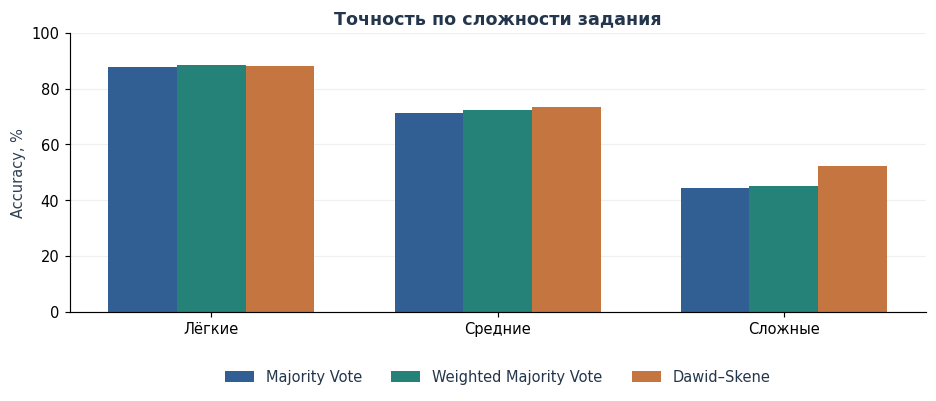

In [21]:
fig, ax = plt.subplots(figsize=(8.8, 3.7), layout="constrained")
x = np.arange(len(LEVELS))
width = 0.24
for index, method in enumerate(METHODS):
    ax.bar(
        x + (index - 1) * width,
        100 * accuracy_by_level[method],
        width,
        color=METHOD_COLORS[method],
        label=method,
    )
ax.set(
    title="Точность по сложности задания",
    ylabel="Accuracy, %",
    ylim=(0, 100),
    xticks=x,
    xticklabels=LEVELS,
)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncols=3,
    frameon=False,
)
ax.yaxis.grid(alpha=0.18)
ax.set_axisbelow(True)
plt.show()

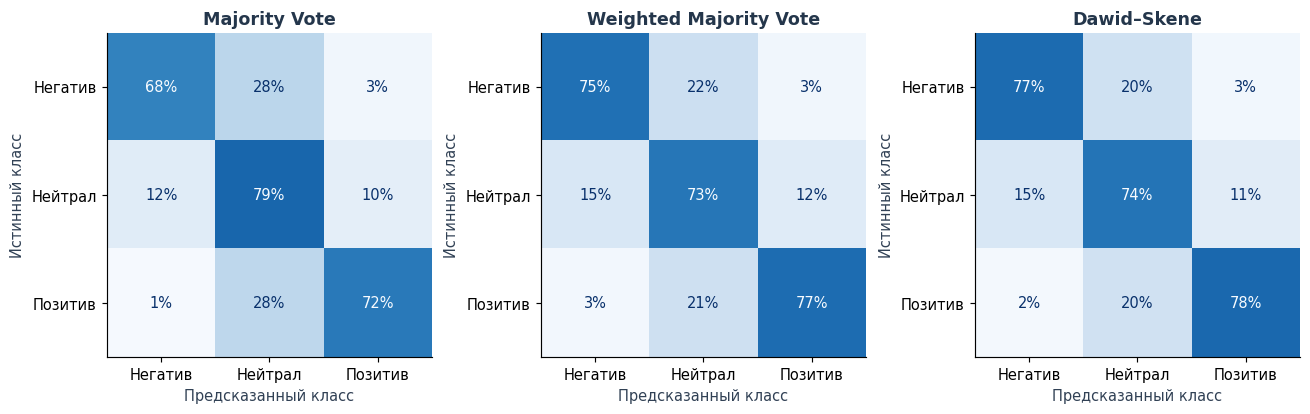

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.8), layout="constrained")
short_names = ["Негатив", "Нейтрал", "Позитив"]
for ax, method in zip(axes, METHODS, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        test_truth,
        predictions[method][test_positions],
        labels=CLASS_IDS,
        display_labels=short_names,
        normalize="true",
        values_format=".0%",
        cmap="Blues",
        ax=ax,
        colorbar=False,
        im_kw={"vmin": 0, "vmax": 1},
    )
    ax.set(
        title=method,
        xlabel="Предсказанный класс",
        ylabel="Истинный класс",
    )
plt.show()

## 6. Почему данные похожи на реальные

В таблице собраны измеренные свойства датасета и то, каким реальным явлениям они соответствуют. Значения получены из текущей симуляции, поэтому их можно пересчитать при повторном запуске.

Согласие получилось низким: **α ≈ 0.2**. Это осознанно шумная краудразметка, а не экспертная. В реальных субъективных задачах согласие тоже часто невысокое, особенно на 3 классах; при этом **Majority Vote заметно превосходит отдельного асессора** — типичный эффект краудсорсинга. Экспертная разметка дала бы более высокий α, но и стоила бы дороже; именно поэтому в реальных проектах используют перекрытие, gold-вопросы и агрегацию.

In [23]:
test_annotations = annotations.loc[
    annotations["task_id"].isin(tasks.loc[tasks["split"].eq("test"), "task_id"])
]
single_rater_accuracy = (
    tasks.set_index("task_id").loc[test_annotations["task_id"], "gold_label"].to_numpy()
    == test_annotations["label"].to_numpy()
).mean()
mv_accuracy = result.loc["Majority Vote", "Accuracy"]

realism_rows = [
    (
        "Заданий / оценок",
        f"{len(tasks)} / {len(annotations):,}".replace(",", " "),
        "Небольшой датасет с многократным перекрытием — типичный фрагмент краудсорсингового проекта.",
    ),
    (
        "Оценок на задание",
        f"{int(sizes.min())}–{int(sizes.max())}, в среднем {sizes.mean():.2f}",
        "В микрозадачах обычно назначают 3–5 исполнителей; 7 — усиленный контроль.",
    ),
    (
        "Нагрузка асессоров",
        f"{int(workload.min())}–{int(workload.max())}, медиана {int(workload.median())}",
        "Активность исполнителей распределена неравномерно: есть новички и «тяжёлые» исполнители.",
    ),
    (
        "Точность на калибровке",
        f"{worker_stats['calib_accuracy'].min():.1%}–"
        f"{worker_stats['calib_accuracy'].max():.1%}, "
        f"средняя {calib_rate:.1%}",
        "Разный опыт и мотивация: сильные и слабые асессоры сосуществуют в одном пуле.",
    ),
    (
        "Согласие пар",
        f"{pair_agreement.mean():.1%}",
        "Субъективная тональность допускает разные прочтения; полного согласия нет.",
    ),
    (
        "Krippendorff's alpha",
        f"{alpha_all:.3f}",
        "Низкое согласие на шумной краудразметке; на лёгких заданиях выше, на сложных около нуля.",
    ),
    (
        "Единогласие / ничьи",
        f"{unanimous.mean():.1%} / {tied.mean():.1%}",
        "При 3–7 оценках и трёх классах ничьи и разногласия — обычное дело.",
    ),
    (
        "Согласие по сложности",
        " → ".join(f"{100 * by_level.loc[level, 'Согласие']:.1f}%" for level in LEVELS),
        "Чем сложнее задание, тем хуже согласие; так же ведут себя реальные асессоры.",
    ),
    (
        "Эталон → голоса",
        "; ".join(
            f"{name}: {class_share.loc[name, 'Эталон']:.1%}→"
            f"{class_share.loc[name, 'Ответы асессоров']:.1%}"
            for name in CLASS_NAMES
        ),
        "Умеренный дисбаланс классов и небольшой сдвиг ответов относительно эталона.",
    ),
    (
        "Отдельный ответ / MV",
        f"{single_rater_accuracy:.1%} / {mv_accuracy:.1%}",
        "Агрегация использует независимые ошибки и заметно поднимает точность.",
    ),
]

display(
    pd.DataFrame(
        realism_rows,
        columns=["Показатель", "Значение", "Почему похоже на реальные данные"],
    )
    .style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
)

Показатель,Значение,Почему похоже на реальные данные
Заданий / оценок,2000 / 8 156,Небольшой датасет с многократным перекрытием — типичный фрагмент краудсорсингового проекта.
Оценок на задание,"3–7, в среднем 4.08",В микрозадачах обычно назначают 3–5 исполнителей; 7 — усиленный контроль.
Нагрузка асессоров,"59–508, медиана 171",Активность исполнителей распределена неравномерно: есть новички и «тяжёлые» исполнители.
Точность на калибровке,"24.0%–92.5%, средняя 61.4%",Разный опыт и мотивация: сильные и слабые асессоры сосуществуют в одном пуле.
Согласие пар,47.6%,Субъективная тональность допускает разные прочтения; полного согласия нет.
Krippendorff's alpha,0.203,"Низкое согласие на шумной краудразметке; на лёгких заданиях выше, на сложных около нуля."
Единогласие / ничьи,18.4% / 13.3%,При 3–7 оценках и трёх классах ничьи и разногласия — обычное дело.
Согласие по сложности,54.6% → 44.7% → 36.3%,"Чем сложнее задание, тем хуже согласие; так же ведут себя реальные асессоры."
Эталон → голоса,Негативный: 28.1%→29.7%; Нейтральный: 40.9%→40.3%; Позитивный: 30.9%→30.0%,Умеренный дисбаланс классов и небольшой сдвиг ответов относительно эталона.
Отдельный ответ / MV,60.7% / 73.7%,Агрегация использует независимые ошибки и заметно поднимает точность.


## 7. Устойчивость на пяти симуляциях

Один набор данных может дать случайное преимущество. Повторяю всю процедуру на пяти независимых симуляциях с фиксированными гиперпараметрами и смотрю, сохраняется ли порядок методов.

In [24]:
def evaluate_seed(
    seed: int,
    sim_config: SimulationConfig,
    agg_config: AggregationConfig,
) -> dict[str, float]:
    """Regenerate a dataset and evaluate all aggregation methods."""
    simulated = simulate_dataset(sim_config, seed)
    result = run_pipeline(simulated, sim_config, agg_config)
    positions = np.flatnonzero(simulated.tasks["split"].eq("test").to_numpy())
    truth = simulated.tasks["gold_label"].to_numpy()[positions]
    return {
        **{
            method: accuracy_score(truth, result.predictions[method][positions])
            for method in METHODS
        },
        "α": krippendorff_alpha_nominal(
            task_rating_units(simulated.annotations),
            len(CLASS_IDS),
        ),
    }

In [25]:
robustness = pd.DataFrame(
    [
        {"seed": seed, **evaluate_seed(seed, SIM_CONFIG, AGG_CONFIG)}
        for seed in ROBUSTNESS_SEEDS
    ]
).set_index("seed")

summary = pd.DataFrame(
    {
        "Среднее": robustness[list(METHODS)].mean(),
        "Std": robustness[list(METHODS)].std(),
        "Min": robustness[list(METHODS)].min(),
        "Max": robustness[list(METHODS)].max(),
        "Побед": [
            int(robustness[list(METHODS)].idxmax(axis=1).eq(method).sum())
            for method in METHODS
        ],
    }
)
display(robustness.style.format({**dict.fromkeys(METHODS, "{:.2%}"), "α": "{:.3f}"}))
display(
    summary.style.format(
        {
            "Среднее": "{:.2%}",
            "Std": "{:.2%}",
            "Min": "{:.2%}",
            "Max": "{:.2%}",
            "Побед": "{:.0f}",
        }
    )
)

wmv_wins = int(
    (robustness["Weighted Majority Vote"] > robustness["Majority Vote"]).sum()
)
ds_wins = int((robustness["Dawid–Skene"] > robustness["Weighted Majority Vote"]).sum())
print(
    f"Weighted MV > MV: {wmv_wins}/{len(ROBUSTNESS_SEEDS)} симуляций; "
    f"DS > Weighted MV: {ds_wins}/{len(ROBUSTNESS_SEEDS)}."
)

,Majority Vote,Weighted Majority Vote,Dawid–Skene,α
seed,,,,
42,73.69%,74.62%,76.00%,0.203
43,74.50%,76.25%,77.31%,0.205
44,76.12%,78.94%,80.44%,0.242
45,74.50%,78.00%,79.75%,0.231
46,74.81%,76.31%,78.81%,0.223


,Среднее,Std,Min,Max,Побед
Majority Vote,74.72%,0.89%,73.69%,76.12%,0
Weighted Majority Vote,76.83%,1.68%,74.62%,78.94%,0
Dawid–Skene,78.46%,1.81%,76.00%,80.44%,5


Weighted MV > MV: 5/5 симуляций; DS > Weighted MV: 5/5.


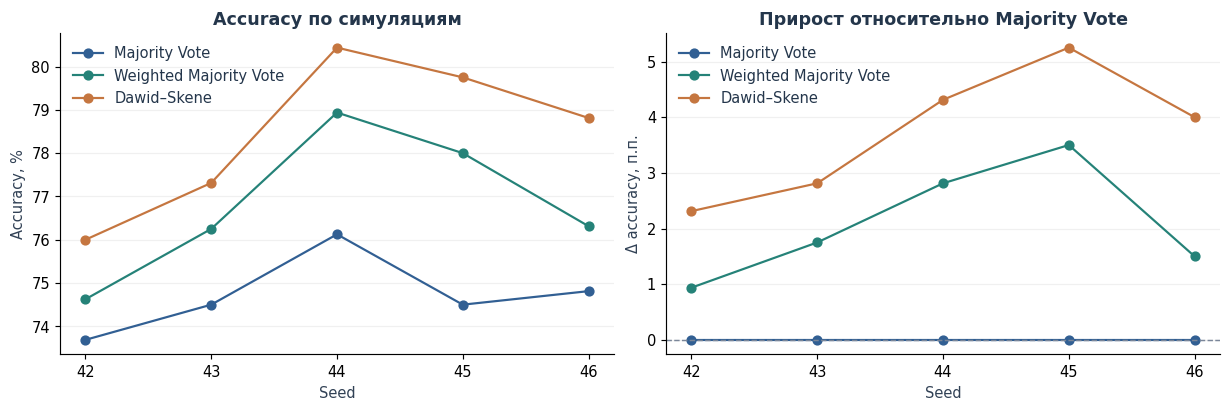

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 3.8), layout="constrained")
seeds = robustness.index.to_numpy()
for method in METHODS:
    axes[0].plot(
        seeds,
        100 * robustness[method],
        "o-",
        color=METHOD_COLORS[method],
        label=method,
    )
    axes[1].plot(
        seeds,
        100 * (robustness[method] - robustness["Majority Vote"]),
        "o-",
        color=METHOD_COLORS[method],
        label=method,
    )
axes[0].set(
    title="Accuracy по симуляциям",
    xlabel="Seed",
    ylabel="Accuracy, %",
    xticks=seeds,
)
axes[1].axhline(0, color="#7a8699", lw=1, ls="--")
axes[1].set(
    title="Прирост относительно Majority Vote",
    xlabel="Seed",
    ylabel="Δ accuracy, п.п.",
    xticks=seeds,
)
axes[0].legend(frameon=False)
axes[1].legend(frameon=False)
for ax in axes:
    ax.yaxis.grid(alpha=0.18)
    ax.set_axisbelow(True)
plt.show()

## 8. Выводы

Чтобы выводы были основаны на данных, ниже — итоговые числа основного прогона (seed 42) и сводка по пяти симуляциям.

- На основном датасете **Dawid–Skene** дал **76.0% accuracy** и **76.4% macro-F1**; **Weighted Majority Vote** — **74.6%** и **75.0%**; **Majority Vote** — **73.7%** и **73.9%**.
- Прирост Dawid–Skene относительно Majority Vote: **+2.31 п.п.**, 95%-й интервал **[+0.44; +4.06]**; по macro-F1 — **+2.47 п.п.**, **[+0.63; +4.23]**. Прирост взвешенного голосования **+0.94 п.п.**, интервал **[-0.31; +2.25]** — статистически неотличим от нуля.
- На **сложных** заданиях разрыв максимален: **52.1%** у Dawid–Skene против **45.0%** у Weighted MV и **44.3%** у MV. На **лёгких** заданиях методы близки (**88.6%**, **88.1%** и **87.7%**); взвешенное голосование там даже немного точнее.
- По recall Dawid–Skene лучше распознаёт негатив и позитив (**77.0%** и **78.3%** против **68.1%** и **71.5%** у MV), но хуже — нейтраль (**73.7%** против **78.9%**). Поэтому его общий прирост скромнее, чем выигрыш на крайних классах.
- По пяти симуляциям **Dawid–Skene выигрывает 5/5** (в среднем **78.5%** против **76.8%** у Weighted MV и **74.7%** у MV). Weighted MV выигрывает у MV тоже 5/5. Это не зависит от одного удачного seed.
- **Данные ведут себя как реальная шумная разметка:** α≈0.20, agreement падает с ростом сложности (≈55% → ≈36%), у асессоров разная точность (≈24–92%), а агрегация поднимает accuracy с ≈61% (один ответ) до ≈74% (Majority Vote).
- **Weighted Majority Vote** — простой и дешёвый способ использовать gold-калибровку; **Dawid–Skene** не требует золотых меток и в среднем точнее, но сложнее и чувствителен к допущениям.

Ограничения: ошибки асессоров в симуляции независимы при данном правильном классе, а сложность задания общая для всех. Dawid–Skene эти зависимости не моделирует. Кроме того, проверена одна процедура генерации и пять seed-ов; для реального внедрения нужны данные и дополнительные методы (например, GLAD, учитывающий сложность задания, или MACE, устойчивый к спамерам).

**Практический вывод:** при наличии gold-калибровки стоит начинать с Weighted Majority Vote; если gold нет или важна точность на сложных заданиях — использовать Dawid–Skene, желательно с калибровкой и проверкой на нескольких разбиениях.

## Источники

- Dawid, A. P. и Skene, A. M. (1979). Maximum likelihood estimation of observer error-rates using the EM algorithm. *Applied Statistics*, 28(1), 20–28. [DOI](https://doi.org/10.2307/2346806)
- Snow, R., O'Connor, B., Jurafsky, D. и Ng, A. Y. (2008). Cheap and fast — but is it good? Evaluating non-expert annotations for natural language tasks. *EMNLP 2008*. [ACL Anthology](https://aclanthology.org/D08-1027/)
- Whitehill, J., Wu, T., Bergsma, J., Movellan, J. R. и Ruvolo, P. L. (2009). Whose vote should count more? Optimal integration of labels from labelers of unknown expertise. *NeurIPS 2009*. [Статья](https://proceedings.neurips.cc/paper_files/paper/2009/hash/f899139df5e1059396431415e770c6dd-Abstract.html)
- Artstein, R. и Poesio, M. (2008). Inter-coder agreement for computational linguistics. *Computational Linguistics*, 34(4), 555–596. [ACL Anthology](https://aclanthology.org/J08-4004/)
- Krippendorff, K. (2004). *Content Analysis: An Introduction to Its Methodology* (2nd ed.). Sage.